# Classificação de Pedra, Papel e Tesoura com CNN — Modelo 09

**Objetivo:** construir uma CNN própria em PyTorch para classificar imagens em `paper`, `rock` e `scissors`, analisar o conjunto de dados, comparar um baseline com quatro experimentos controlados e avaliar a configuração selecionada.

**Protocolo:** as imagens oficiais de treino são separadas por sequência de captura em treino e validação. A validação orienta a comparação e a seleção do modelo. O conjunto oficial de teste não é consultado até a avaliação final, uma única vez. Todas as transformações de entrada usam 64×64 pixels, e as decisões aleatórias usam a semente 42.

> Execute o notebook de cima para baixo com **Restart Kernel and Run All**. Os resultados da tabela e a conclusão são produzidos pelas células, não devem ser preenchidos com valores inventados. O kernel precisa ter PyTorch, torchvision, scikit-learn, Pillow, Matplotlib e Seaborn disponíveis; o notebook não instala pacotes silenciosamente.


## 1. Ambiente e reprodutibilidade

Configuramos as sementes de Python, NumPy e PyTorch e solicitamos operações determinísticas quando suportadas. Os DataLoaders usam sementes próprias e `num_workers=0` para evitar aleatoriedade oculta de subprocessos. O pré-processamento de validação é determinístico.


In [1]:
import copy
import random
import re
import time
import urllib.request
import zipfile
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
from IPython.display import display, Markdown

SEED = 42
IMAGE_SIZE = 64
BATCH_SIZE = 64
EPOCHS = 8
LEARNING_RATE = 1e-3
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")


def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    if hasattr(torch.backends, "cudnn"):
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False


set_seed()
print(f"Dispositivo: {DEVICE} | semente: {SEED} | entrada: {IMAGE_SIZE}×{IMAGE_SIZE}")


Dispositivo: cpu | semente: 42 | entrada: 64×64


## 2. Preparação e identificação dos dados

Usamos o Rock-Paper-Scissors disponibilizado pela TensorFlow Datasets (Laurence Moroney). Se as duas pastas esperadas já estiverem presentes, o notebook usa os arquivos locais; caso contrário, baixa e extrai os arquivos de origem. A exploração inicial é feita somente sobre a pasta oficial de treino. A pasta de teste é reservada para a última seção.


In [2]:
DATA_ROOT = Path("dataset")
TRAIN_DIR = DATA_ROOT / "rps"
TEST_DIR = DATA_ROOT / "rps-test-set"

if not TRAIN_DIR.is_dir() or not TEST_DIR.is_dir():
    DATA_ROOT.mkdir(parents=True, exist_ok=True)
    datasets_to_prepare = [
        (TRAIN_DIR, "rps.zip", "https://storage.googleapis.com/tensorflow-1-public/course2/week4/rps.zip"),
        (TEST_DIR, "rps-test-set.zip", "https://storage.googleapis.com/tensorflow-1-public/course2/week4/rps-test-set.zip"),
    ]
    for dataset_dir, archive_name, url in datasets_to_prepare:
        if dataset_dir.is_dir():
            continue
        archive_path = DATA_ROOT / archive_name
        if not archive_path.exists():
            print(f"Baixando {archive_name}...")
            urllib.request.urlretrieve(url, archive_path)
        print(f"Extraindo {archive_name}...")
        with zipfile.ZipFile(archive_path) as archive:
            archive.extractall(DATA_ROOT)

if not TRAIN_DIR.is_dir() or not TEST_DIR.is_dir():
    raise FileNotFoundError(f"Esperadas as pastas {TRAIN_DIR} e {TEST_DIR} após preparar o dataset.")

EVAL_TRANSFORM = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
])
raw_train_dataset = datasets.ImageFolder(TRAIN_DIR)
train_eval_dataset = datasets.ImageFolder(TRAIN_DIR, transform=EVAL_TRANSFORM)
classes = raw_train_dataset.classes
class_to_idx = raw_train_dataset.class_to_idx

if classes != ["paper", "rock", "scissors"]:
    raise ValueError(f"Classes inesperadas ou em ordem incorreta: {classes}")
if raw_train_dataset.samples != train_eval_dataset.samples:
    raise RuntimeError("A ordem dos arquivos mudou entre o dataset de exploração e o de treino.")

print(f"Diretório de treino: {TRAIN_DIR.resolve()}")
print(f"Classes (mapeamento ImageFolder): {class_to_idx}")
print(f"Imagens de treino disponíveis para divisão: {len(raw_train_dataset)}")


Diretório de treino: C:\projects\cnn-rock-paper-scissors\dataset\rps
Classes (mapeamento ImageFolder): {'paper': 0, 'rock': 1, 'scissors': 2}
Imagens de treino disponíveis para divisão: 2520


## 3. Descrição e análise exploratória

Cada exemplo é uma imagem rotulada com um dos três gestos: `paper` (papel), `rock` (pedra) ou `scissors` (tesoura). A próxima inspeção mede a quantidade por classe, dimensões e modos de cor **antes** do redimensionamento, além de verificar se há imagens ilegíveis. Nenhum dado do teste é aberto nesta etapa.


Amostras no conjunto de treino por classe:
  paper: 840 (33.3%)
  rock: 840 (33.3%)
  scissors: 840 (33.3%)
Total: 2520 | imagens legíveis: 2520 | ilegíveis: 0
Modos de cor: {'RGBA': 2520}
Resolução original (largura × altura):
  300×300: 2520 (100.0%)


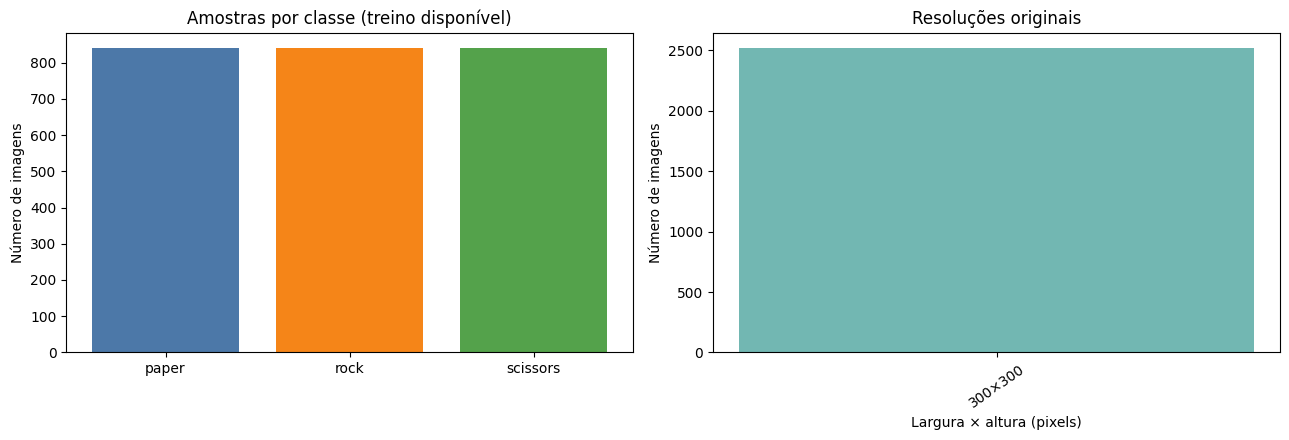

In [3]:
raw_class_counts = Counter(raw_train_dataset.targets)
image_records = []
unreadable_images = []

for image_path, label in raw_train_dataset.samples:
    try:
        with Image.open(image_path) as image:
            width, height = image.size
            color_mode = image.mode
            image.verify()
        image_records.append({
            "path": image_path,
            "class": classes[label],
            "width": width,
            "height": height,
            "mode": color_mode,
        })
    except (OSError, ValueError) as error:
        unreadable_images.append((image_path, str(error)))

resolution_counts = Counter((row["width"], row["height"]) for row in image_records)
mode_counts = Counter(row["mode"] for row in image_records)
print("Amostras no conjunto de treino por classe:")
for class_name in classes:
    count = raw_class_counts[class_to_idx[class_name]]
    print(f"  {class_name}: {count} ({count / len(raw_train_dataset):.1%})")
print(f"Total: {len(raw_train_dataset)} | imagens legíveis: {len(image_records)} | ilegíveis: {len(unreadable_images)}")
print(f"Modos de cor: {dict(mode_counts)}")
print("Resolução original (largura × altura):")
for (width, height), count in resolution_counts.most_common():
    print(f"  {width}×{height}: {count} ({count / max(len(image_records), 1):.1%})")

if unreadable_images:
    print("Arquivos ilegíveis encontrados:")
    for image_path, error in unreadable_images[:20]:
        print(f"  {image_path}: {error}")
    raise RuntimeError("Corrija ou remova explicitamente as imagens ilegíveis antes do treinamento.")
if len(image_records) != len(raw_train_dataset):
    raise RuntimeError("A inspeção não cobriu todas as imagens de treino.")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].bar(classes, [raw_class_counts[class_to_idx[name]] for name in classes], color=["#4C78A8", "#F58518", "#54A24B"])
axes[0].set_title("Amostras por classe (treino disponível)")
axes[0].set_ylabel("Número de imagens")
axes[1].bar([f"{w}×{h}" for (w, h), _ in resolution_counts.most_common()], [n for _, n in resolution_counts.most_common()], color="#72B7B2")
axes[1].set_title("Resoluções originais")
axes[1].set_xlabel("Largura × altura (pixels)")
axes[1].set_ylabel("Número de imagens")
axes[1].tick_params(axis="x", rotation=35)
fig.tight_layout()
plt.show()


**Leitura da EDA:** as contagens e gráficos acima são calculados dos arquivos locais nesta execução. A entrada do modelo será redimensionada para 64×64; isso reduz o custo computacional, mas a transformação força todas as imagens ao mesmo formato e pode alterar proporções. A inspeção também reporta os modos de cor e interrompe o fluxo se encontrar arquivos ilegíveis, em vez de ocultar o problema.


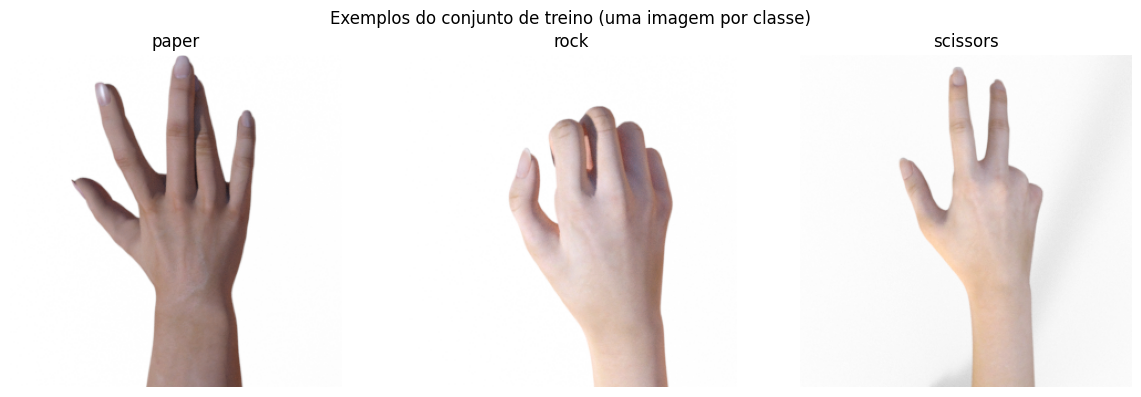

In [4]:
fig, axes = plt.subplots(1, len(classes), figsize=(12, 4))
for class_index, class_name in enumerate(classes):
    sample_index = next(i for i, label in enumerate(raw_train_dataset.targets) if label == class_index)
    image_path, _ = raw_train_dataset.samples[sample_index]
    with Image.open(image_path) as image:
        axes[class_index].imshow(image.convert("RGB"))
    axes[class_index].set_title(class_name)
    axes[class_index].axis("off")
fig.suptitle("Exemplos do conjunto de treino (uma imagem por classe)")
fig.tight_layout()
plt.show()


**Limitações e possíveis vieses:** as imagens de exemplo mostram mãos isoladas em fundos muito claros e com enquadramento semelhante. Essa regularidade pode permitir que o modelo use pistas do fundo ou da apresentação, e não somente do gesto, e pode limitar o desempenho em fotos com outras iluminações, fundos, câmeras ou oclusões. As classes de gesto têm a mesma contagem no conjunto observado quando isso é confirmado pela EDA; isso não implica equilíbrio de pessoas ou condições de captura. Não há metadados demográficos confiáveis para medir representatividade por tom de pele, idade ou gênero, então não fazemos afirmações sobre esses grupos.


## 4. Partição sem vazamento entre sequências

Os nomes do dataset terminam em um número de quadro, por exemplo `paper01-000.png`. Para reduzir o vazamento de quadros quase idênticos da mesma sequência entre treino e validação, agrupamos pelo prefixo anterior ao último hífen e reservamos uma sequência inteira de cada classe para validação. A escolha usa a semente 42. A fração de validação decorre do número de sequências (e pode não ser exatamente 20%); a separação por grupos e a cobertura das três classes são verificadas abaixo. O teste oficial continua intocado.


In [5]:
def capture_group(image_path):
    stem = Path(image_path).stem
    match = re.match(r"^(.*)-\d+$", stem)
    if match is None:
        raise ValueError(f"Nome fora do padrão classe-sequência-quadro: {Path(image_path).name}")
    class_name = Path(image_path).parent.name
    return f"{class_name}/{match.group(1)}"


all_targets = np.asarray(raw_train_dataset.targets)
all_groups = np.asarray([capture_group(path) for path, _ in raw_train_dataset.samples])
train_groups = set()
val_groups = set()

for class_index, class_name in enumerate(classes):
    class_groups = np.unique(all_groups[all_targets == class_index])
    if len(class_groups) < 2:
        raise ValueError(f"A classe {class_name} precisa de pelo menos duas sequências para divisão por grupo.")
    class_train_groups, class_val_groups = train_test_split(
        class_groups, test_size=1, random_state=SEED
    )
    train_groups.update(class_train_groups.tolist())
    val_groups.update(class_val_groups.tolist())

train_indices = np.flatnonzero(np.isin(all_groups, list(train_groups))).tolist()
val_indices = np.flatnonzero(np.isin(all_groups, list(val_groups))).tolist()
train_dataset = Subset(train_eval_dataset, train_indices)
val_dataset = Subset(train_eval_dataset, val_indices)

assert train_groups.isdisjoint(val_groups)
assert set(train_indices).isdisjoint(val_indices)
assert set(train_indices).union(val_indices) == set(range(len(raw_train_dataset)))
assert set(all_targets[train_indices]) == set(range(len(classes)))
assert set(all_targets[val_indices]) == set(range(len(classes)))

print(f"Sequências totais: {len(set(all_groups))} | treino: {len(train_groups)} | validação: {len(val_groups)}")
print(f"Imagens: treino={len(train_indices)} ({len(train_indices)/len(all_targets):.1%}), validação={len(val_indices)} ({len(val_indices)/len(all_targets):.1%})")
for class_index, class_name in enumerate(classes):
    n_train = int(np.sum(all_targets[train_indices] == class_index))
    n_val = int(np.sum(all_targets[val_indices] == class_index))
    print(f"{class_name}: treino={n_train}, validação={n_val}")


Sequências totais: 21 | treino: 18 | validação: 3
Imagens: treino=2160 (85.7%), validação=360 (14.3%)
paper: treino=720, validação=120
rock: treino=720, validação=120
scissors: treino=720, validação=120


A validação é composta por sequências inteiras que não aparecem no treino; isso é mais rigoroso que dividir quadros aleatoriamente quando imagens de uma mesma captura são correlacionadas. A proporção de validação é informada pela célula e resulta da granularidade das sequências, não de uma escolha que consulte o teste. Todos os experimentos reutilizam exatamente esses mesmos índices.


In [6]:
AUGMENT_TRANSFORM = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ToTensor(),
])
augmented_full_dataset = datasets.ImageFolder(TRAIN_DIR, transform=AUGMENT_TRANSFORM)
if augmented_full_dataset.samples != raw_train_dataset.samples:
    raise RuntimeError("O dataset aumentado não preservou a ordem dos arquivos originais.")
augmented_train_dataset = Subset(augmented_full_dataset, train_indices)


def make_loader(dataset, shuffle, seed=SEED):
    generator = torch.Generator().manual_seed(seed)
    return DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=shuffle, num_workers=0, generator=generator)


val_loader = make_loader(val_dataset, shuffle=False)


## 5. Arquitetura própria da CNN

A rede abaixo é construída camada por camada em PyTorch, sem pesos pré-treinados. A entrada é RGB 64×64. Cada bloco aplica convolução 3×3 com padding 1, ReLU e max-pooling 2×2. A quantidade de filtros aumenta de 16 para 32 (e para 64 no experimento mais profundo) para representar características progressivamente mais complexas; pooling reduz resolução e custo. O pooling adaptativo para 4×4 mantém a cabeça classificadora compacta e compatível com as duas profundidades. A camada final retorna três logits para `CrossEntropyLoss`.


In [7]:
class RPSConvNet(nn.Module):
    def __init__(self, use_dropout=False, use_batch_norm=False, extra_block=False):
        super().__init__()
        self.use_batch_norm = use_batch_norm

        def make_block(in_channels, out_channels):
            layers = [nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1)]
            if use_batch_norm:
                layers.append(nn.BatchNorm2d(out_channels))
            layers.extend([nn.ReLU(inplace=True), nn.MaxPool2d(kernel_size=2, stride=2)])
            return nn.Sequential(*layers)

        self.block1 = make_block(3, 16)
        self.block2 = make_block(16, 32)
        self.block3 = make_block(32, 64) if extra_block else None
        final_channels = 64 if extra_block else 32
        self.adaptive_pool = nn.AdaptiveAvgPool2d((4, 4))
        self.dropout = nn.Dropout(p=0.5) if use_dropout else nn.Identity()
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(final_channels * 4 * 4, 128),
            nn.ReLU(inplace=True),
            self.dropout,
            nn.Linear(128, len(classes)),
        )

    def forward(self, inputs):
        features = self.block1(inputs)
        features = self.block2(features)
        if self.block3 is not None:
            features = self.block3(features)
        features = self.adaptive_pool(features)
        return self.classifier(features)


baseline_for_inspection = RPSConvNet().to(DEVICE)
parameter_count = sum(parameter.numel() for parameter in baseline_for_inspection.parameters() if parameter.requires_grad)
print(baseline_for_inspection)
print(f"Parâmetros treináveis no baseline: {parameter_count:,}")
del baseline_for_inspection


RPSConvNet(
  (block1): Sequential(
    (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU(inplace=True)
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (block2): Sequential(
    (0): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU(inplace=True)
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (adaptive_pool): AdaptiveAvgPool2d(output_size=(4, 4))
  (dropout): Identity()
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=512, out_features=128, bias=True)
    (2): ReLU(inplace=True)
    (3): Identity()
    (4): Linear(in_features=128, out_features=3, bias=True)
  )
)
Parâmetros treináveis no baseline: 71,139


## 6. Baseline e experimentos controlados

Comparamos um baseline com quatro mudanças, uma por vez. Mantemos partições, resolução, batch size, otimizador Adam, taxa de aprendizado, épocas e semente iguais. As variações são: (1) data augmentation apenas no treino; (2) dropout 0,5 na cabeça classificadora; (3) Batch Normalization após as convoluções; (4) um terceiro bloco convolucional. Cada experimento parte de uma inicialização nova e usa a mesma validação. O conjunto de teste não participa da comparação.


In [8]:
def train_one_model(model, train_loader, val_loader, epochs=EPOCHS):
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    history = {"train_loss": [], "val_loss": [], "train_accuracy": [], "val_accuracy": []}
    best_state = None
    best_val_accuracy = -1.0
    best_val_loss = float("inf")
    best_epoch = 0

    for epoch in range(epochs):
        model.train()
        train_loss_sum = 0.0
        train_correct = 0
        train_total = 0
        for images, labels in train_loader:
            images = images.to(DEVICE)
            labels = labels.to(DEVICE)
            optimizer.zero_grad(set_to_none=True)
            logits = model(images)
            loss = criterion(logits, labels)
            loss.backward()
            optimizer.step()
            train_loss_sum += loss.item() * labels.size(0)
            train_correct += (logits.argmax(dim=1) == labels).sum().item()
            train_total += labels.size(0)

        model.eval()
        val_loss_sum = 0.0
        val_correct = 0
        val_total = 0
        with torch.no_grad():
            for images, labels in val_loader:
                images = images.to(DEVICE)
                labels = labels.to(DEVICE)
                logits = model(images)
                loss = criterion(logits, labels)
                val_loss_sum += loss.item() * labels.size(0)
                val_correct += (logits.argmax(dim=1) == labels).sum().item()
                val_total += labels.size(0)

        epoch_train_loss = train_loss_sum / train_total
        epoch_val_loss = val_loss_sum / val_total
        epoch_train_accuracy = train_correct / train_total
        epoch_val_accuracy = val_correct / val_total
        history["train_loss"].append(epoch_train_loss)
        history["val_loss"].append(epoch_val_loss)
        history["train_accuracy"].append(epoch_train_accuracy)
        history["val_accuracy"].append(epoch_val_accuracy)

        if (epoch_val_accuracy > best_val_accuracy or
                (epoch_val_accuracy == best_val_accuracy and epoch_val_loss < best_val_loss)):
            best_val_accuracy = epoch_val_accuracy
            best_val_loss = epoch_val_loss
            best_epoch = epoch + 1
            best_state = copy.deepcopy(model.state_dict())
        print(
            f"Época {epoch + 1:02d}/{epochs} | "
            f"treino loss={epoch_train_loss:.4f}, acc={epoch_train_accuracy:.3f} | "
            f"val loss={epoch_val_loss:.4f}, acc={epoch_val_accuracy:.3f}"
        )

    if best_state is None:
        raise RuntimeError("Nenhum checkpoint de validação foi produzido.")
    model.load_state_dict(best_state)
    model.eval()
    return history, best_epoch, best_val_accuracy, best_val_loss


O treinador guarda, para cada configuração, o checkpoint com melhor acurácia de validação (desempatando pela menor perda). As curvas armazenam métricas por época para treino e validação. Essa seleção não olha o teste.


In [9]:
EXPERIMENTS = [
    {
        "name": "Baseline",
        "hypothesis": "CNN simples aprende os padrões básicos dos três gestos.",
        "change": "Duas convoluções; sem augmentation, dropout ou BatchNorm.",
        "model_kwargs": {},
        "augmentation": False,
    },
    {
        "name": "Data augmentation",
        "hypothesis": "Variações moderadas de orientação reduzem dependência da pose exata.",
        "change": "RandomHorizontalFlip + RandomRotation(15°), somente no treino.",
        "model_kwargs": {},
        "augmentation": True,
    },
    {
        "name": "Dropout",
        "hypothesis": "Dropout 0,5 na cabeça reduz coadaptação e overfitting.",
        "change": "Ativa Dropout(0.5) antes da camada de saída.",
        "model_kwargs": {"use_dropout": True},
        "augmentation": False,
    },
    {
        "name": "Batch Normalization",
        "hypothesis": "Normalizar ativações pode estabilizar e acelerar o treinamento.",
        "change": "Adiciona BatchNorm2d após cada convolução.",
        "model_kwargs": {"use_batch_norm": True},
        "augmentation": False,
    },
    {
        "name": "Maior profundidade",
        "hypothesis": "Um terceiro bloco pode extrair características mais complexas.",
        "change": "Adiciona Conv(32→64) + ReLU + MaxPool.",
        "model_kwargs": {"extra_block": True},
        "augmentation": False,
    },
]

models = {}
histories = {}
experiment_results = {}

for experiment in EXPERIMENTS:
    print(f"\n=== {experiment['name']} ===")
    set_seed(SEED)
    model = RPSConvNet(**experiment["model_kwargs"]).to(DEVICE)
    selected_train_dataset = augmented_train_dataset if experiment["augmentation"] else train_dataset
    experiment_train_loader = make_loader(selected_train_dataset, shuffle=True, seed=SEED)
    start_time = time.perf_counter()
    history, best_epoch, best_val_accuracy, best_val_loss = train_one_model(
        model, experiment_train_loader, val_loader
    )
    elapsed_seconds = time.perf_counter() - start_time
    models[experiment["name"]] = model
    histories[experiment["name"]] = history
    experiment_results[experiment["name"]] = {
        "hypothesis": experiment["hypothesis"],
        "change": experiment["change"],
        "best_epoch": best_epoch,
        "val_accuracy": best_val_accuracy,
        "val_loss": best_val_loss,
        "train_accuracy_at_best": history["train_accuracy"][best_epoch - 1],
        "seconds": elapsed_seconds,
        "parameters": sum(p.numel() for p in model.parameters() if p.requires_grad),
    }
    print(f"Melhor checkpoint: época {best_epoch}, val acc={best_val_accuracy:.3f}, val loss={best_val_loss:.4f}")



=== Baseline ===
Época 01/8 | treino loss=1.0878, acc=0.374 | val loss=1.0748, acc=0.333
Época 02/8 | treino loss=0.9446, acc=0.585 | val loss=0.7890, acc=0.914
Época 03/8 | treino loss=0.5501, acc=0.807 | val loss=0.4641, acc=0.967
Época 04/8 | treino loss=0.3173, acc=0.897 | val loss=0.2900, acc=0.989
Época 05/8 | treino loss=0.1864, acc=0.961 | val loss=0.3067, acc=0.906
Época 06/8 | treino loss=0.1168, acc=0.986 | val loss=0.2592, acc=0.978
Época 07/8 | treino loss=0.0972, acc=0.978 | val loss=0.1687, acc=1.000
Época 08/8 | treino loss=0.0615, acc=0.993 | val loss=0.1580, acc=0.981
Melhor checkpoint: época 7, val acc=1.000, val loss=0.1687

=== Data augmentation ===
Época 01/8 | treino loss=1.0960, acc=0.353 | val loss=1.0931, acc=0.333
Época 02/8 | treino loss=1.0421, acc=0.494 | val loss=1.0578, acc=0.664
Época 03/8 | treino loss=0.7623, acc=0.669 | val loss=0.7534, acc=0.517
Época 04/8 | treino loss=0.4949, acc=0.808 | val loss=0.5976, acc=0.761
Época 05/8 | treino loss=0.3320,

## 7. Resultados dos experimentos

A tabela é montada automaticamente com o melhor resultado de validação de cada modelo. A conclusão compara cada alteração ao baseline sem afirmar melhora quando os números não a sustentarem. Revise as hipóteses e as diferenças observadas após executar o treinamento.


In [10]:
baseline_val_accuracy = experiment_results["Baseline"]["val_accuracy"]
print(f"{'Experimento':<24} {'Época':>5} {'Acc. val.':>10} {'Loss val.':>10} {'Acc. treino':>12} {'Parâmetros':>12} {'Δ acc.':>9}  Conclusão")
print("-" * 126)
for experiment in EXPERIMENTS:
    name = experiment["name"]
    result = experiment_results[name]
    delta = result["val_accuracy"] - baseline_val_accuracy
    if name == "Baseline":
        conclusion = "referência"
    elif delta > 0.005:
        conclusion = "melhora observada na validação"
    elif delta < -0.005:
        conclusion = "resultado inferior ao baseline"
    else:
        conclusion = "resultado semelhante ao baseline"
    print(
        f"{name:<24} {result['best_epoch']:>5} {result['val_accuracy']:>10.3f} "
        f"{result['val_loss']:>10.4f} {result['train_accuracy_at_best']:>12.3f} "
        f"{result['parameters']:>12,} {delta:>+9.3f}  {conclusion}"
    )
    print(f"  Hipótese: {result['hypothesis']}")
    print(f"  Alteração: {result['change']}")


Experimento              Época  Acc. val.  Loss val.  Acc. treino   Parâmetros    Δ acc.  Conclusão
------------------------------------------------------------------------------------------------------------------------------
Baseline                     7      1.000     0.1687        0.978       71,139    +0.000  referência
  Hipótese: CNN simples aprende os padrões básicos dos três gestos.
  Alteração: Duas convoluções; sem augmentation, dropout ou BatchNorm.
Data augmentation            5      1.000     0.3275        0.894       71,139    +0.000  resultado semelhante ao baseline
  Hipótese: Variações moderadas de orientação reduzem dependência da pose exata.
  Alteração: RandomHorizontalFlip + RandomRotation(15°), somente no treino.
Dropout                      4      0.989     0.3546        0.835       71,139    -0.011  resultado inferior ao baseline
  Hipótese: Dropout 0,5 na cabeça reduz coadaptação e overfitting.
  Alteração: Ativa Dropout(0.5) antes da camada de saída.
Batch N

A acurácia e a perda de validação são as métricas usadas para comparar os experimentos; a acurácia de treino ajuda a identificar uma possível diferença de generalização, mas não substitui a validação. O modelo selecionado é o de maior acurácia de validação; em empate, escolhemos a menor perda. A seguir, as curvas apresentam treino e validação do modelo selecionado.


Modelo selecionado pela validação: Baseline
Acurácia de validação: 1.000


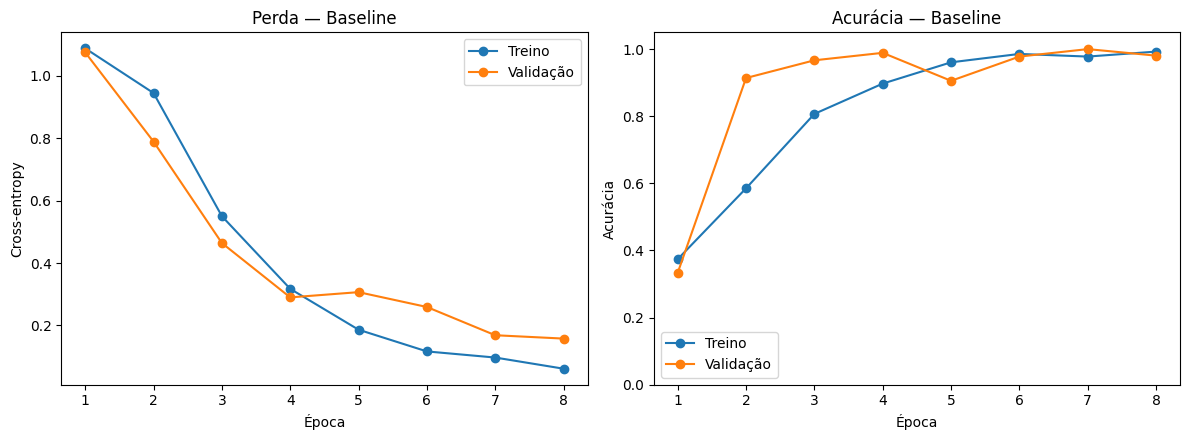

In [11]:
best_model_name = max(
    experiment_results,
    key=lambda name: (experiment_results[name]["val_accuracy"], -experiment_results[name]["val_loss"]),
)
selected_model = models[best_model_name]
selected_history = histories[best_model_name]
selected_model.eval()
print(f"Modelo selecionado pela validação: {best_model_name}")
print(f"Acurácia de validação: {experiment_results[best_model_name]['val_accuracy']:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
epoch_numbers = np.arange(1, len(selected_history["train_loss"]) + 1)
axes[0].plot(epoch_numbers, selected_history["train_loss"], marker="o", label="Treino")
axes[0].plot(epoch_numbers, selected_history["val_loss"], marker="o", label="Validação")
axes[0].set_title(f"Perda — {best_model_name}")
axes[0].set_xlabel("Época")
axes[0].set_ylabel("Cross-entropy")
axes[0].legend()
axes[1].plot(epoch_numbers, selected_history["train_accuracy"], marker="o", label="Treino")
axes[1].plot(epoch_numbers, selected_history["val_accuracy"], marker="o", label="Validação")
axes[1].set_title(f"Acurácia — {best_model_name}")
axes[1].set_xlabel("Época")
axes[1].set_ylabel("Acurácia")
axes[1].set_ylim(0, 1.05)
axes[1].legend()
fig.tight_layout()
plt.show()


## 8. Grad-CAM na validação

Para não consultar o conjunto de teste antes da avaliação final, os mapas Grad-CAM são calculados em seis imagens de validação (duas por classe) com o modelo selecionado. O mapa mostra regiões que contribuíram para o logit da classe prevista; ele é uma explicação visual aproximada, não uma prova causal nem uma métrica de acurácia.


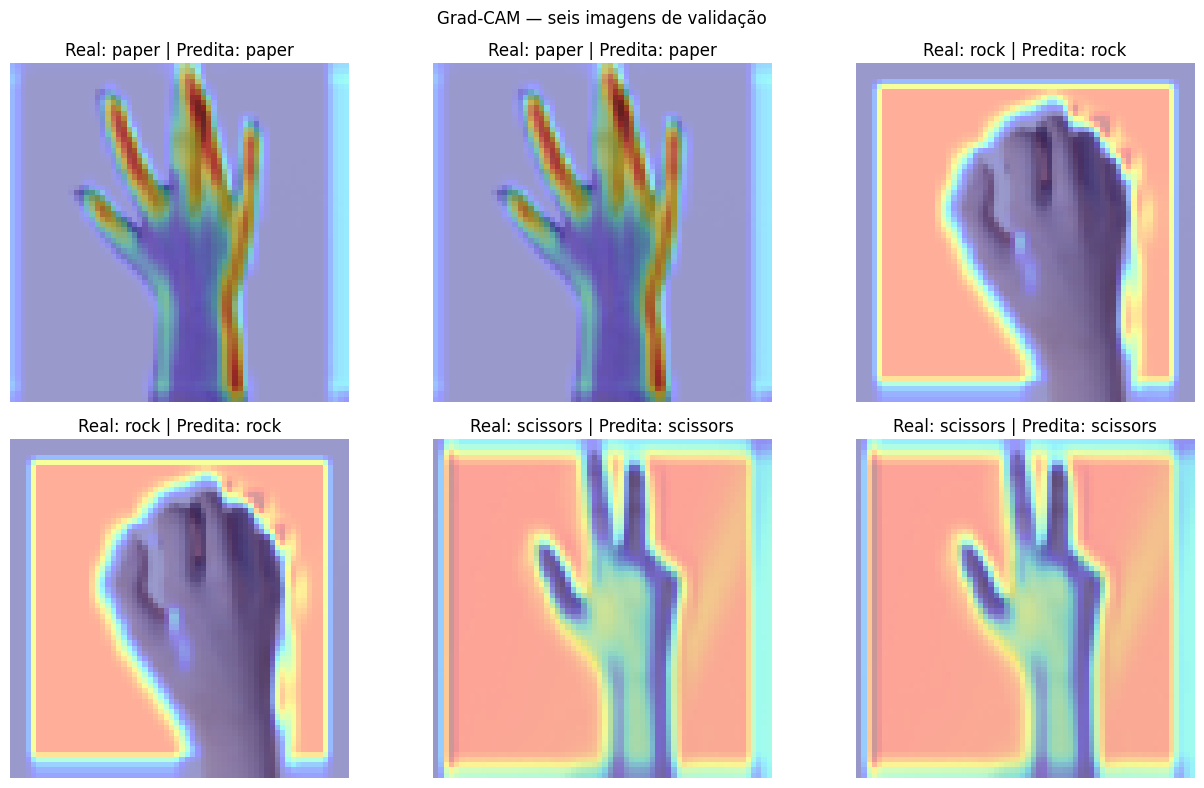

In [12]:
val_examples = []
for class_index, class_name in enumerate(classes):
    class_val_indices = [index for index in val_indices if raw_train_dataset.targets[index] == class_index]
    if len(class_val_indices) < 2:
        raise RuntimeError(f"A validação não possui duas imagens da classe {class_name} para Grad-CAM.")
    val_examples.extend(class_val_indices[:2])

activations = {}
gradients = {}


def save_activation_gradient(module, inputs, output):
    activations["value"] = output
    output.register_hook(lambda gradient: gradients.__setitem__("value", gradient))


target_layer = selected_model.block2[0]
hook_handle = target_layer.register_forward_hook(save_activation_gradient)
fig, axes = plt.subplots(2, 3, figsize=(13, 8))

for axis, sample_index in zip(axes.flatten(), val_examples):
    image_tensor, true_label = train_eval_dataset[sample_index]
    input_tensor = image_tensor.unsqueeze(0).to(DEVICE)
    selected_model.zero_grad(set_to_none=True)
    gradients.clear()
    logits = selected_model(input_tensor)
    predicted_label = int(logits.argmax(dim=1).item())
    logits[0, predicted_label].backward()

    feature_maps = activations["value"].detach()
    feature_gradients = gradients["value"].detach()
    channel_weights = feature_gradients.mean(dim=(2, 3), keepdim=True)
    cam = torch.relu((channel_weights * feature_maps).sum(dim=1, keepdim=True))
    cam = F.interpolate(cam, size=(IMAGE_SIZE, IMAGE_SIZE), mode="bilinear", align_corners=False)[0, 0]
    cam = cam.cpu().numpy()
    cam_max = float(cam.max())
    if cam_max > 0:
        cam = cam / cam_max

    image_np = image_tensor.permute(1, 2, 0).numpy()
    axis.imshow(image_np)
    axis.imshow(cam, cmap="jet", alpha=0.4, vmin=0, vmax=1)
    axis.set_title(f"Real: {classes[true_label]} | Predita: {classes[predicted_label]}")
    axis.axis("off")

hook_handle.remove()
selected_model.zero_grad(set_to_none=True)
fig.suptitle("Grad-CAM — seis imagens de validação")
fig.tight_layout()
plt.show()


## 9. Avaliação final no teste — executar uma única vez

A escolha do modelo já foi concluída com validação. Somente agora o código abre o conjunto oficial de teste, percorre seus exemplos uma vez e calcula acurácia, precisão, revocação, F1-score por classe, acurácia por classe e matriz de confusão. Não use esses resultados para selecionar novamente arquitetura, épocas ou hiperparâmetros.


Modelo avaliado: Baseline
Amostras de teste avaliadas nesta passagem: 372
Acurácia global no teste: 0.8199

Métricas por classe:
Classe         Precisão  Revocação   F1-score  Acc. classe   Suporte
paper            0.8462     0.7097     0.7719       0.7097       124
rock             0.6964     0.9435     0.8014       0.9435       124
scissors         1.0000     0.8065     0.8929       0.8065       124


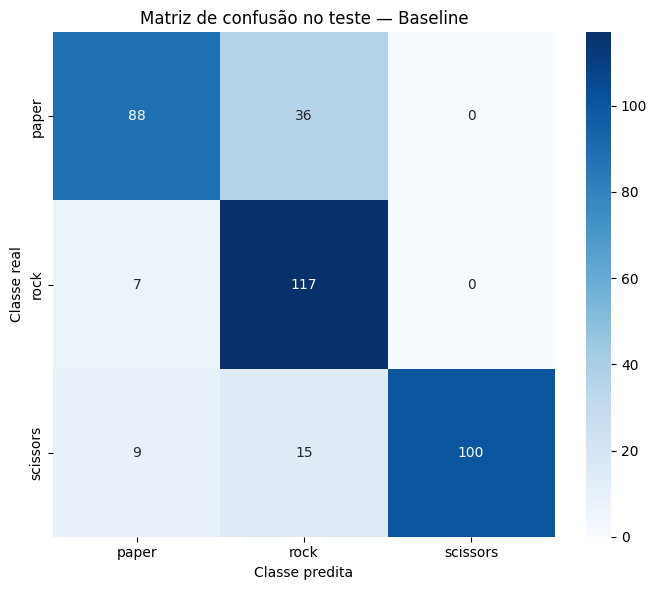

In [13]:
test_dataset = datasets.ImageFolder(TEST_DIR, transform=EVAL_TRANSFORM)
if test_dataset.classes != classes:
    raise ValueError(f"As classes do teste ({test_dataset.classes}) não correspondem às classes de treino ({classes}).")
test_loader = make_loader(test_dataset, shuffle=False, seed=SEED)

y_test = []
y_test_pred = []
selected_model.eval()
with torch.no_grad():
    for images, labels in test_loader:
        logits = selected_model(images.to(DEVICE))
        y_test.extend(labels.numpy().tolist())
        y_test_pred.extend(logits.argmax(dim=1).cpu().numpy().tolist())

test_accuracy = accuracy_score(y_test, y_test_pred)
test_cm = confusion_matrix(y_test, y_test_pred, labels=list(range(len(classes))))
test_report = classification_report(
    y_test,
    y_test_pred,
    labels=list(range(len(classes))),
    target_names=classes,
    output_dict=True,
    zero_division=0,
)
print(f"Modelo avaliado: {best_model_name}")
print(f"Amostras de teste avaliadas nesta passagem: {len(y_test)}")
print(f"Acurácia global no teste: {test_accuracy:.4f}")
print("\nMétricas por classe:")
print(f"{'Classe':<12} {'Precisão':>10} {'Revocação':>10} {'F1-score':>10} {'Acc. classe':>12} {'Suporte':>9}")
for class_index, class_name in enumerate(classes):
    support = int(test_cm[class_index].sum())
    class_accuracy = test_cm[class_index, class_index] / support if support else 0.0
    metrics = test_report[class_name]
    print(
        f"{class_name:<12} {metrics['precision']:>10.4f} {metrics['recall']:>10.4f} "
        f"{metrics['f1-score']:>10.4f} {class_accuracy:>12.4f} {support:>9}"
    )

fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(test_cm, annot=True, fmt="d", cmap="Blues", xticklabels=classes, yticklabels=classes, ax=ax)
ax.set_xlabel("Classe predita")
ax.set_ylabel("Classe real")
ax.set_title(f"Matriz de confusão no teste — {best_model_name}")
fig.tight_layout()
plt.show()


## 10. Uso de IA e correções críticas

**Registro de uso de IA (06/11/2026):** assistente de IA integrado ao VS Code foi usado para comparar o notebook com o enunciado, revisar risco de vazamento, propor e aplicar mudanças no código e documentação. A execução de verificação deste ambiente concluiu as 14 células de código sem erros em CPU; o grupo ainda deve repetir `Restart Kernel and Run All` no kernel da entrega, entender o código e adaptar este registro para refletir fielmente o uso real.

| Interação / problema encontrado | Correção aplicada | Verificação a fazer pelo grupo |
|---|---|---|
| A divisão anterior não preservava uma semente explícita e podia espalhar quadros correlacionados entre treino e validação. | Semente fixa e divisão por grupos de captura derivados do prefixo do arquivo; as asserções confirmam grupos e índices disjuntos e cobertura de todas as imagens. | Executar as células e confirmar número de sequências, contagens por partição e asserções. |
| O fluxo anterior acessava imagens/rótulos do teste antes de terminar experimentos e avaliação de Grad-CAM. | EDA e Grad-CAM usam somente treino/validação; o teste é carregado e percorrido somente após a seleção baseada na validação. | Revisar o código da última seção e não reexecutar células de teste para tomar decisões de modelagem. |
| Uma descrição anterior atribuía ao conjunto diversidade demográfica e geração CGI sem evidência local suficiente. | Documentação atual limita as conclusões a aspectos visíveis nas amostras e registra que não há rótulos demográficos confiáveis. | Conferir a fonte do dataset e manter afirmações sobre a população representada apenas se houver metadados verificáveis. |

**Reprodutibilidade:** a semente é definida antes de cada experimento; arquitetura, resolução, épocas, batch size e taxa de aprendizado são impressos ou definidos nas células. Nesta execução, o modelo selecionado obteve acurácia de 81,99% no teste (372 imagens), avaliado em uma única passagem. Para a entrega, reinicie o kernel, execute tudo até o fim e mantenha as saídas correspondentes à execução sem erros.


In [15]:
class_lines = []
for class_name in classes:
    metrics = test_report[class_name]
    class_lines.append(
        f"- **{class_name}:** precisão {metrics['precision']:.3f}, revocação {metrics['recall']:.3f}, "
        f"F1 {metrics['f1-score']:.3f} (n={int(metrics['support'])})."
    )

summary_markdown = f"""### Q&A

- **Qual modelo foi selecionado sem usar o teste?** {best_model_name}, com acurácia de validação de {experiment_results[best_model_name]['val_accuracy']:.3f}.
- **Como foi o resultado na avaliação final?** A acurácia no conjunto de teste foi {test_accuracy:.3f}; o teste foi percorrido uma única vez nesta etapa final.

### Data Analysis Key Findings

- O conjunto analisado para treino contém {len(raw_train_dataset)} imagens nas classes {', '.join(classes)}; consulte as contagens e resoluções impressas na EDA.
- A divisão por sequência usou semente {SEED}, manteve os grupos de captura separados e resultou em {len(train_indices)} imagens de treino e {len(val_indices)} de validação.
- Métricas do teste por classe:
{chr(10).join(class_lines)}
- A matriz de confusão e seis mapas Grad-CAM da validação estão apresentados acima. O dataset não tem metadados demográficos confiáveis; a regularidade de fundo e enquadramento das amostras limita conclusões sobre generalização para fotos do mundo real.
"""
display(Markdown(summary_markdown))


### Q&A

- **Qual modelo foi selecionado sem usar o teste?** Baseline, com acurácia de validação de 1.000.
- **Como foi o resultado na avaliação final?** A acurácia no conjunto de teste foi 0.820; o teste foi percorrido uma única vez nesta etapa final.

### Data Analysis Key Findings

- O conjunto analisado para treino contém 2520 imagens nas classes paper, rock, scissors; consulte as contagens e resoluções impressas na EDA.
- A divisão por sequência usou semente 42, manteve os grupos de captura separados e resultou em 2160 imagens de treino e 360 de validação.
- Métricas do teste por classe:
- **paper:** precisão 0.846, revocação 0.710, F1 0.772 (n=124).
- **rock:** precisão 0.696, revocação 0.944, F1 0.801 (n=124).
- **scissors:** precisão 1.000, revocação 0.806, F1 0.893 (n=124).
- A matriz de confusão e seis mapas Grad-CAM da validação estão apresentados acima. O dataset não tem metadados demográficos confiáveis; a regularidade de fundo e enquadramento das amostras limita conclusões sobre generalização para fotos do mundo real.
